# Práctica N°03: Simulación de eventos discretos

# 5.3. Modelo de inventario probabilístico

In [1]:
%matplotlib inline

import random
import numpy as np
import math
import matplotlib.pyplot as plt

## Escenario: parámetros del enunciado

P0 = 20 · P = 100 · p = 20 · L = 5 · h = 100 · r = 150 · llegada de clientes ~ Poisson(λ)

Supuestos (la guía no los fija): horizonte T = 30, λ = 5, demanda por cliente G ~ Uniforme discreta {1,...,5} y precio unitario del pedido c(y) escalonado (130 si y < 5, 110 si 5 ≤ y < 10, 100 si y ≥ 10), de modo que el costo de un pedido es y·c(y) [Sec. 5.6 Rios08].

In [2]:
Xant = 434287492

M = 99999.0
T = 30.0
Lambda = 5.0

P_0 = 20     # cantidad de inventario inicial
P = 100     # maximo nivel de inventario
p = 20      # cantidad de producto a pedir si no hay pedidos pendientes
L = 5       # tiempo que tarda en llegar un pedido

h = 100 # valor a pagar por una unidad del producto en almacenamiento
r = 150 # valor de venta al publico

demanda =0

t_array = []
x_array = []
y_array = []
H_array = []
C_array = []
R_array = []
demanda_array = []

In [3]:
def gencongru():
    global Xant
    a = 134775813
    c = 1
    m = 2**32
    Xnext = (a * Xant + c) % m
    Xant = Xnext
    U = Xnext / m
    return U

def GenerarExp(Lambda):
    U = gencongru()
    X = -(math.log(1-U))/float(Lambda)
    return X

def func_c(y):
    # modificado: costo del pedido = y * costo por unidad, el costo por unidad depende de y [Sec. 5.6 Rios08]
    if y < 5:
        val = 130
    if (y >= 5)&(y < 10):      # modificado (base: y <= 5)
        val = 110
    if (y>=10):
        val = 100
    return y*val


def Llegada_cliente(t_suc):
    global x, y, t, C, H, R, N_C_minus, N_C_plus, t_0, var_nivel0, P, h, r, L, x_array, y_array, t_array, H_array, C_array, R_array, demanda_array, demanda
    H = H + (t_suc - t)*h*x
    t = t_suc

    demanda = random.randint(1, 5)

    if (demanda <= x):
        R = R + demanda*r
        x = x - demanda
        N_C_plus = N_C_plus + 1
    else:
        R = R + (x*r)          # modificado (base: R += R + (x*r))
        x = 0.0
        N_C_minus = N_C_minus + 1

    if (x == 0) & (var_nivel0 == 0):   # modificado: instante en que el inventario llega a cero
        var_nivel0 = t

    if (x <= p)&(y == 0):
        y = P - x
        TSuc['tP'] = t + L
    Y = GenerarExp(Lambda)

    if ( (t + Y) < T ):
        TSuc['tC'] = t + Y
    demanda_array.append(demanda)
    H_array.append(H)
    C_array.append(C)
    R_array.append(R)
    t_array.append(t)
    x_array.append(x)
    y_array.append(y)

def Llegada_pedido(t_suc):
    global x, y, t, C, H, R, N_C_minus, N_C_plus, t_0, var_nivel0, P, h, x_array, y_array, t_array, H_array, C_array, R_array, demanda_array, demanda

    H = H + (t_suc - t)*h*x
    t = t_suc
    C = C + func_c(y)
    x = x + y
    y = 0.0
    if var_nivel0 > 0:
        t_0 = t_0 + (t - var_nivel0)
        var_nivel0 = 0
    demanda_array.append(0)            # modificado: en la llegada de un pedido no hay demanda de cliente
    H_array.append(H)
    C_array.append(C)
    R_array.append(R)
    t_array.append(t)
    x_array.append(x)
    y_array.append(y)

In [4]:
x = P_0
y = N_C_minus = N_C_plus = C = R = H = 0.0
TSuc = {"tC":M, "tP":M}
t = t_suc = t_0 = var_nivel0 = 0.0

random.seed(1)                  # semilla de la demanda para que la corrida sea reproducible

# estado inicial en t = 0 (para que las graficas arranquen en P0, como la Figura 5.9)
t_array.append(t); x_array.append(x); y_array.append(y)
H_array.append(H); C_array.append(C); R_array.append(R); demanda_array.append(0)

Z = GenerarExp(Lambda)

if Z > T:
    beneficio = porc_client_satisf = porc_invent_0 = 0.0
else:
    Llegada_cliente(Z)
    while((TSuc['tP'] != M)|(TSuc['tC']!=M)):
        if TSuc['tC'] < TSuc['tP']:
            t_suc = TSuc['tC']
            TSuc['tC'] = M
            Llegada_cliente(t_suc)
        if TSuc['tP'] < TSuc['tC']:
            t_suc = TSuc['tP']
            TSuc['tP'] = M
            Llegada_pedido(t_suc)
    beneficio = R - C - H
    porc_invent_0 = t_0/t
    porc_client_satisf = N_C_plus / (N_C_plus + N_C_minus)

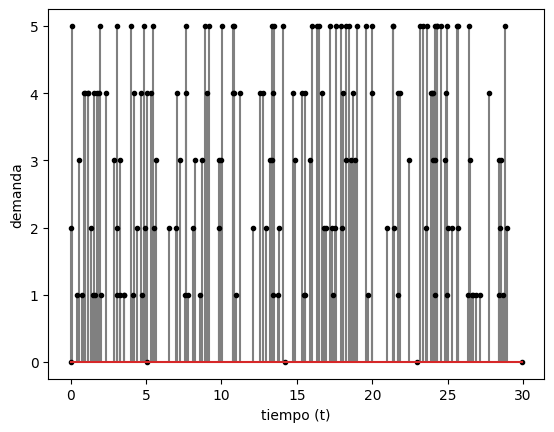

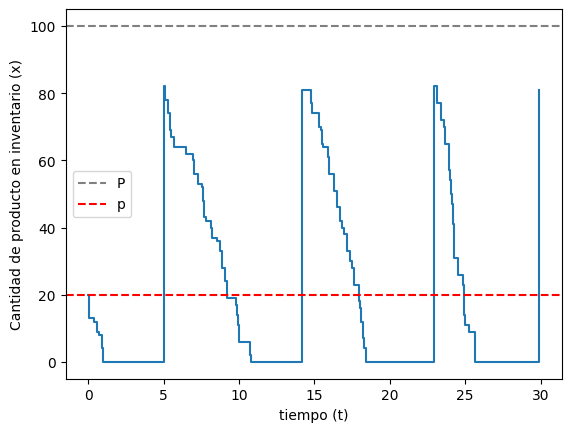

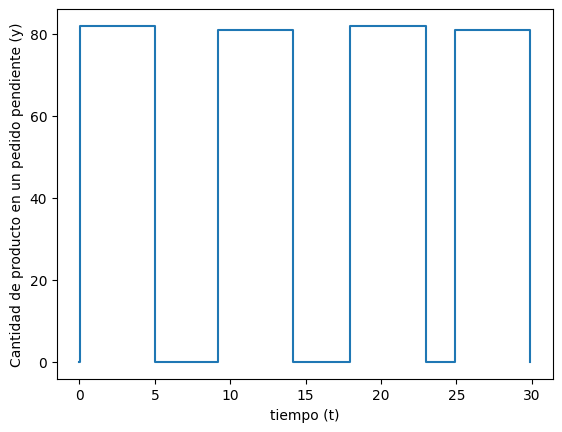

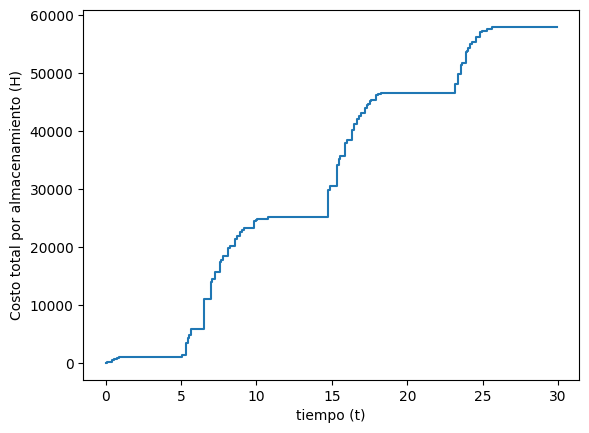

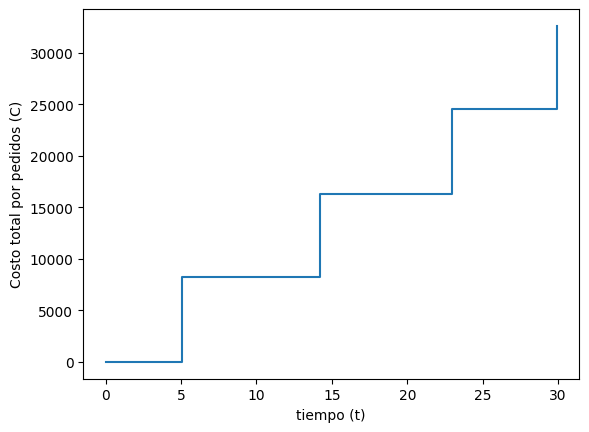

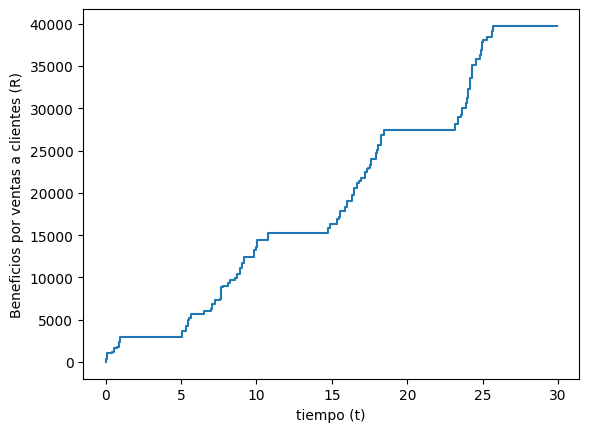

In [5]:
plt.stem(t_array, demanda_array, linefmt='gray', markerfmt='.k')
plt.xlabel('tiempo (t)')
plt.ylabel('demanda')
plt.show()

plt.step(t_array, x_array, where='post')
plt.axhline(P, color='gray', linestyle='--', label='P')
plt.axhline(p, color='red', linestyle='--', label='p')
plt.legend()
plt.xlabel('tiempo (t)')
plt.ylabel('Cantidad de producto en inventario (x)')
plt.show()

plt.step(t_array, y_array, where='post')
plt.xlabel('tiempo (t)')
plt.ylabel('Cantidad de producto en un pedido pendiente (y)')
plt.show()

plt.step(t_array, H_array, where='post')
plt.xlabel('tiempo (t)')
plt.ylabel('Costo total por almacenamiento (H)')
plt.show()

plt.step(t_array, C_array, where='post')
plt.xlabel('tiempo (t)')
plt.ylabel('Costo total por pedidos (C)')
plt.show()

plt.step(t_array, R_array, where='post')
plt.xlabel('tiempo (t)')
plt.ylabel('Beneficios por ventas a clientes (R)')
plt.show()

In [6]:
print("Beneficio: ",beneficio)
print("Porc. clientes satisfechos: ",porc_client_satisf*100)
print("Porc. inventario en cero: ",porc_invent_0*100)

Beneficio:  -50801.99834837215
Porc. clientes satisfechos:  49.03225806451613
Porc. inventario en cero:  54.22342632385061
